# Cartera dedicada · Acciones

**Objetivo.** Aislar la renta variable dentro de una cartera pequeña y homogénea para estudiar su
volatilidad, su dispersión sectorial y su comportamiento dentro del toolkit.

- **Universo:** cinco acciones estadounidenses de sectores distintos (`AAPL`, `JPM`, `JNJ`, `XOM`, `WMT`).
- **Moneda:** USD. La biblioteca no convierte divisas, así que todos los ejemplos usan una sola moneda.
- **Ventana:** desde `2025-01-02` hasta la última sesión disponible.
- **Anualización:** 252 sesiones, el convenio de los activos que cotizan de lunes a viernes.

Datos hasta la última sesión disponible anterior a `END` (2026-11-06).

In [1]:
"""Cartera dedicada de acciones: ingesta, informe y simulación."""

import warnings

from IPython.display import Markdown

from quantfolio import (
    CachedPriceSource,
    MonteCarloParameters,
    Portfolio,
    YahooFinanceSource,
)

#: yfinance todavía usa argumentos ``inplace`` que pandas 3 marca como obsoletos.
warnings.filterwarnings("ignore", message=".*inplace keyword.*")

START = "2025-01-02"
END = "2026-11-06"
TICKERS = ["AAPL", "JPM", "JNJ", "XOM", "WMT"]
WEIGHTS = {"AAPL": 0.20, "JPM": 0.20, "JNJ": 0.20, "XOM": 0.20, "WMT": 0.20}
PERIODS_PER_YEAR = 252

## 1 · Ingesta

`get_many()` descarga las cinco series en lote y cada una se normaliza en un `PriceSeries` con su
ticker, su origen, sus estadísticos y sus precios limpios. La caché CSV evita repetir la descarga
mientras los datos sigan siendo recientes.

In [2]:
source = CachedPriceSource(YahooFinanceSource(), cache_dir="data")
assets = source.get_many(TICKERS, start=START, end=END)

for ticker, asset in assets.items():
    print(
        f"{ticker:>5} | {asset.source:<18} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

 AAPL | Yahoo Finance (cache) | 2025-01-02 → 2026-11-05 | 463 observaciones
  JPM | Yahoo Finance (cache) | 2025-01-02 → 2026-11-05 | 463 observaciones
  JNJ | Yahoo Finance (cache) | 2025-01-02 → 2026-11-05 | 463 observaciones
  XOM | Yahoo Finance (cache) | 2025-01-02 → 2026-11-05 | 463 observaciones
  WMT | Yahoo Finance (cache) | 2025-01-02 → 2026-11-05 | 463 observaciones


## 2 · Cartera

`Portfolio` valida que haya un peso por activo, normaliza los pesos y alinea los calendarios por
intersección. Con cinco acciones estadounidenses la cobertura debería ser completa.

In [3]:
portfolio = Portfolio(assets=assets, weights=WEIGHTS)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

Pesos normalizados:
  AAPL: 20.00%
  JPM: 20.00%
  JNJ: 20.00%
  XOM: 20.00%
  WMT: 20.00%

Diagnóstico de alineación temporal: {'union_dates': 463, 'common_dates': 463, 'coverage': 1.0, 'multi_day_returns': 101, 'multi_day_share': 0.21908893709327548, 'max_gap_days': 4}


## 3 · Informe

El informe Markdown reúne la composición, las métricas anualizadas, la calidad de los datos y las
advertencias de riesgo. Las advertencias se calculan a partir del estado real de la cartera.

In [4]:
Markdown(portfolio.report(periods_per_year=PERIODS_PER_YEAR))

# Informe de la cartera

## 1. Composición

| Activo | Divisa local | Peso |
|---|---|---:|
| AAPL | desconocida | 20.00% |
| JPM | desconocida | 20.00% |
| JNJ | desconocida | 20.00% |
| XOM | desconocida | 20.00% |
| WMT | desconocida | 20.00% |

_La conversión de divisas no se ha evaluado; el análisis conserva la divisa local._

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.1111% |
| Volatilidad diaria | 0.9494% |
| Rentabilidad anualizada aproximada | 28.00% |
| Volatilidad anualizada | 15.07% |
| Error estándar de la rentabilidad anualizada | 11.13% |
| IC 95% de la rentabilidad anualizada | 6.18% - 49.82% |
| Rentabilidad geométrica (CAGR) | 30.80% |
| Deriva del logaritmo usada por Monte Carlo | 26.85% |
| Crecimiento mediano implícito (exp(m)-1) | 30.80% |
| Máxima caída histórica | -17.34% |
| Ratio de Sharpe (rf=0.00%) | 1.86 |
| VaR histórico diario (95%) | 1.30% |
| CVaR histórico diario (95%) | 1.95% |

_Un VaR o CVaR negativo indica que el cuantil de la cola es una ganancia._

_La simulación usa la deriva del logaritmo; su mediana crece a exp(m)-1, no a la rentabilidad aritmética._

## 3. Calidad de los datos

- Activos: 5
- Fechas en la unión de calendarios: 463
- Fechas comunes a todos los activos: 463
- Cobertura tras la alineación: 100.0%
- Intervalos entre retornos que abarcan más de un día natural: 21.9% (máximo 4 días)
- Observaciones de rentabilidad: 462
- Periodo de la muestra: 2025-01-03 → 2026-11-05
- Años de historia: 1.83

**Cobertura por activo**

| Activo | Observaciones | Inicio | Fin |
|---|---:|---|---|
| AAPL | 463 | 2025-01-02 | 2026-11-05 |
| JPM | 463 | 2025-01-02 | 2026-11-05 |
| JNJ | 463 | 2025-01-02 | 2026-11-05 |
| XOM | 463 | 2025-01-02 | 2026-11-05 |
| WMT | 463 | 2025-01-02 | 2026-11-05 |

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.
- El 21.9% de los intervalos entre retornos abarca más de un día natural; la anualización con 252 o 365 periodos es aproximada.

## 4 · Panel analítico

El primer panel muestra la evolución de precios **reajustada a base 100**, para que activos con
precios nominales distintos se puedan comparar. Los otros tres paneles muestran la rentabilidad
acumulada, la matriz de correlación y el valor de la cartera.

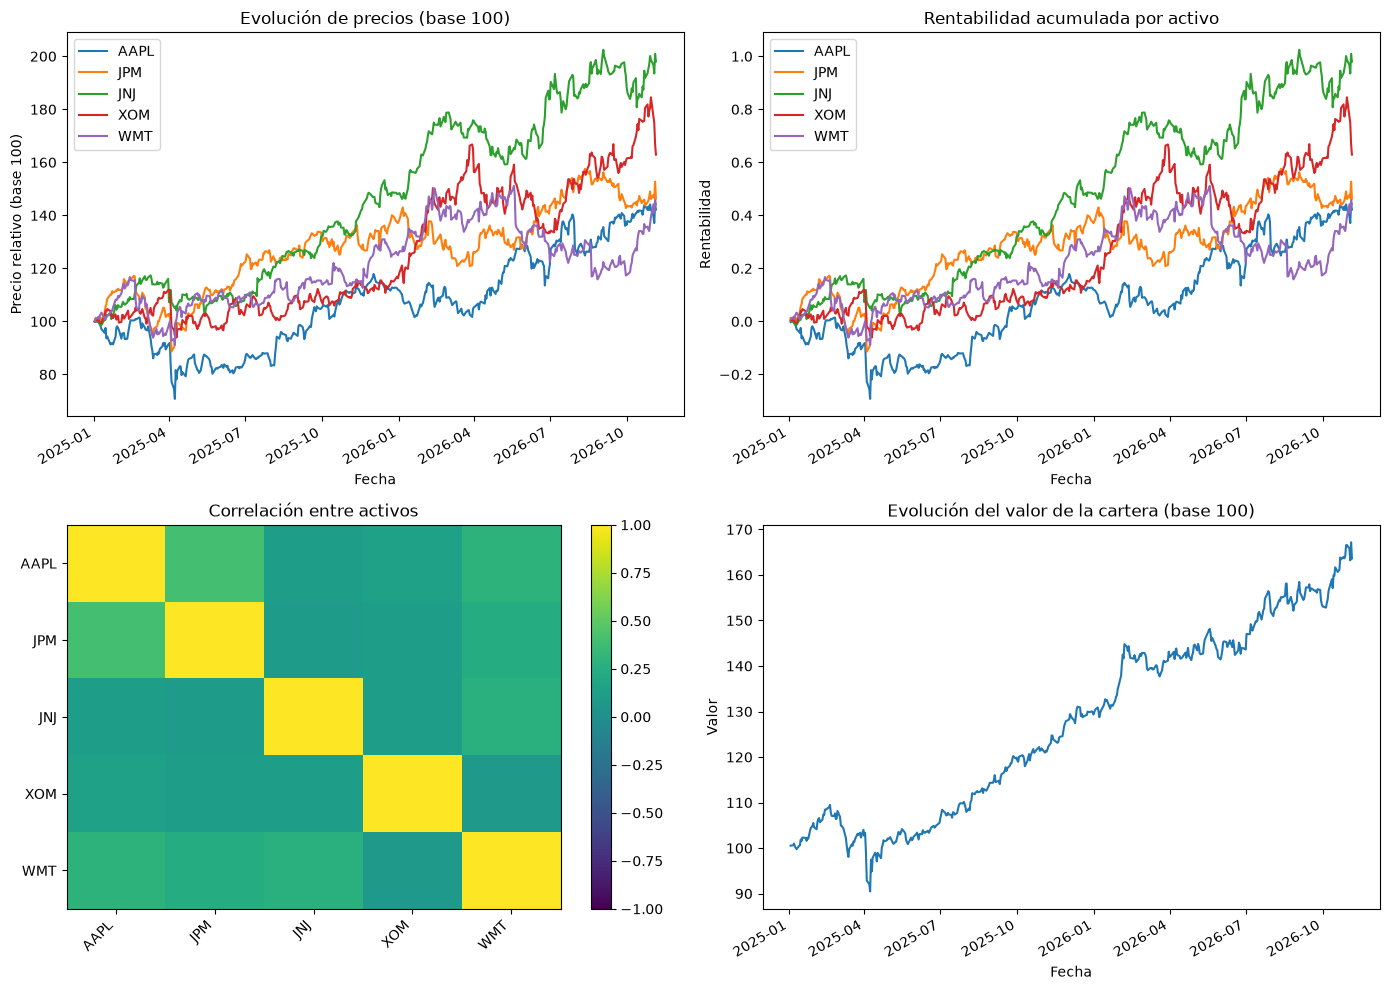

In [5]:
portfolio.plots_report()

## 5 · Simulación Monte Carlo

La simulación usa la deriva y la volatilidad logarítmicas estimadas de la historia. Con 252 pasos,
el horizonte representa un año de sesiones. La distribución final permite leer el abanico de
resultados, no una predicción puntual.

count     2000.00
mean     13224.57
std       2044.84
min       8179.81
5%       10176.39
50%      13010.79
95%      17085.63
max      20941.99
Name: 252, dtype: float64


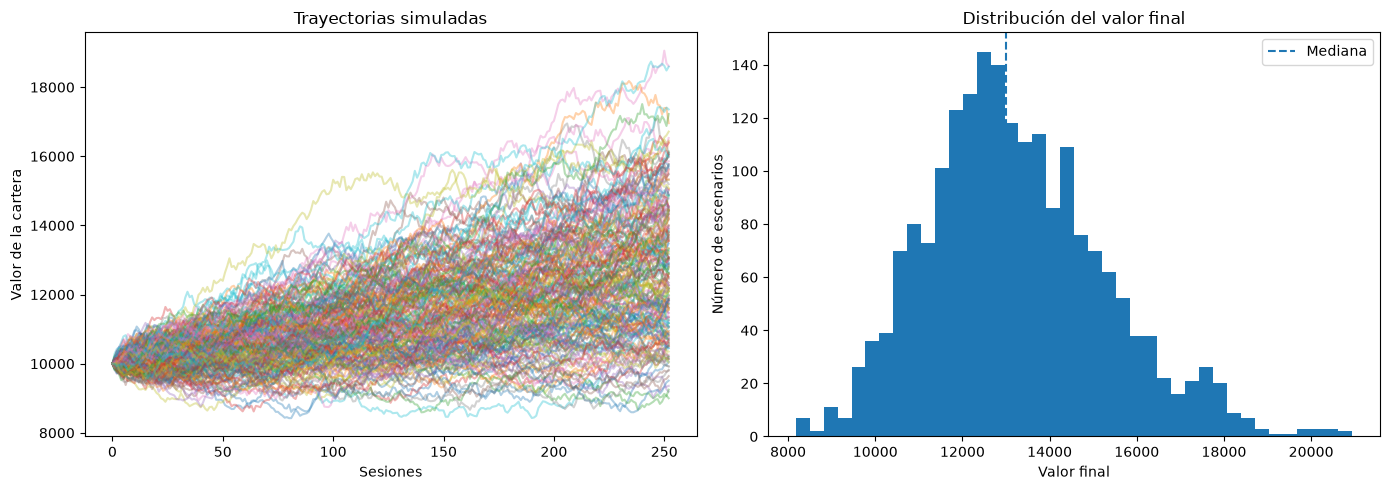

In [6]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))
portfolio.plot_simulation(simulations, max_paths=200)

## 6 · Qué aporta esta clase

Las acciones individuales concentran riesgo idiosincrático: el resultado depende de la empresa, no
solo del mercado. La dispersión sectorial de esta cartera reduce parte de ese riesgo, pero la
correlación entre acciones sigue siendo alta. En una cartera diversificada, esta clase aporta
crecimiento a cambio de una volatilidad claramente superior a la de los bonos.